# Hypothesis Tests and A/B Testing

Compare groups with a clear question, a test, an effect size, and appropriate caveats.

> 🧭 This notebook focuses on practical data work. Examples are intentionally compact and do not cover machine learning.

## Learning goals
- State a null hypothesis and an alternative hypothesis.
- Interpret a p-value without treating it as the probability that the null is true.
- Run a Welch two-sample t-test for a difference in means.
- Consider effect size, confidence intervals, assumptions, and practical importance.

An A/B test compares outcomes across groups. Valid causal interpretation requires an appropriate assignment process, stable measurement, and attention to interference, attrition, and multiple comparisons.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

rng = np.random.default_rng(303)
control = rng.normal(loc=10.0, scale=2.0, size=120)
treatment = rng.normal(loc=10.7, scale=2.2, size=115)
print("Control mean:", round(control.mean(), 3))
print("Treatment mean:", round(treatment.mean(), 3))
print("Observed difference:", round(treatment.mean() - control.mean(), 3))

Control mean: 9.844
Treatment mean: 10.863
Observed difference: 1.019


## Welch's t-test
- Null hypothesis: the population means are equal.
- Alternative hypothesis: the means differ.
- Welch's test does not require equal population variances.
- The p-value quantifies how unusual a result at least this extreme would be under the null model and test assumptions.

t statistic: 3.544
p-value: 0.0005
Difference in sample means: 1.019


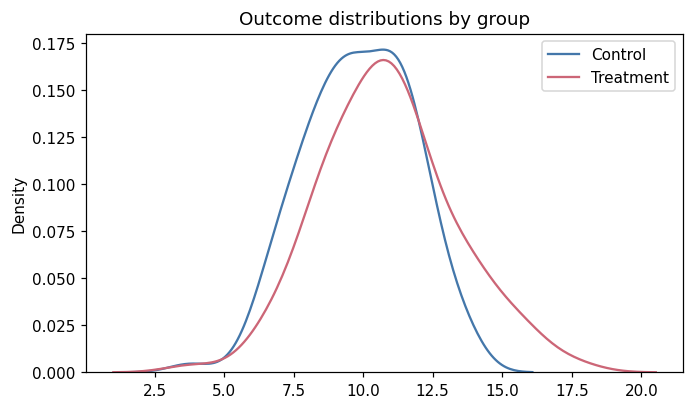

In [2]:
test = stats.ttest_ind(treatment, control, equal_var=False)
difference = treatment.mean() - control.mean()
print("t statistic:", round(test.statistic, 3))
print("p-value:", round(test.pvalue, 4))
print("Difference in sample means:", round(difference, 3))

fig, ax = plt.subplots(figsize=(7, 4))
sns.kdeplot(control, label="Control", color="#4477AA", ax=ax)
sns.kdeplot(treatment, label="Treatment", color="#CC6677", ax=ax)
ax.set_title("Outcome distributions by group")
ax.legend()
plt.show()

## Assumptions and interpretation
- Observations should be independent between and within groups for the basic test.
- Strong skew, small samples, outliers, or clustered observations may require a different approach.
- Report a meaningful effect size and uncertainty, not only whether `p < 0.05`.
- Statistical significance is not the same as business or scientific importance.

In [3]:
# Approximate confidence interval for the difference using Welch-Satterthwaite degrees of freedom.
n1, n0 = len(treatment), len(control)
v1, v0 = treatment.var(ddof=1), control.var(ddof=1)
se_diff = np.sqrt(v1/n1 + v0/n0)
df_welch = (v1/n1 + v0/n0)**2 / ((v1/n1)**2/(n1-1) + (v0/n0)**2/(n0-1))
critical = stats.t.ppf(0.975, df_welch)
ci_diff = (difference - critical*se_diff, difference + critical*se_diff)
print("Approx. 95% CI for mean difference:", tuple(round(v, 3) for v in ci_diff))

Approx. 95% CI for mean difference: (np.float64(0.452), np.float64(1.586))


## Practice
Compare two groups with Welch's t-test. State the null hypothesis, report the difference in means and p-value, and explain why a small p-value is not proof of causality.

In [4]:
group_a = np.array([5.1, 5.3, 4.9, 5.0, 5.2, 5.4, 4.8])
group_b = np.array([5.5, 5.8, 5.2, 5.7, 5.6, 5.4, 5.9])
result = stats.ttest_ind(group_b, group_a, equal_var=False)
print("Mean difference:", group_b.mean() - group_a.mean())
print("p-value:", result.pvalue)

Mean difference: 0.4857142857142849
p-value: 0.001900532615629665
